# Platform Pricing: Who Pays, Who Gets Paid

> Computational Analysis of Social Complexity
>
> Fall 2026, Spencer Lyon

**Prerequisites**

- [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb)
- [Ignition: Chicken-and-Egg, Lock-In, and Tipping](../week10/L10.02_ignition_and_tipping.ipynb)
- {term}`Game theory <game theory>` (week 8)

**Outcomes**

- Formulate a {term}`platform`'s two-sided pricing problem
- Derive and solve first-order conditions numerically in {term}`Julia`
- Explain why optimal platform prices can be zero or negative on one side
- Distinguish {term}`price structure` from {term}`price level` and apply the distinction to real cases

**References**

- Required primary text: [Easley & Kleinberg, *Networks, Crowds, and Markets*, chapter 17](https://www.cs.cornell.edu/home/kleinber/networks-book/networks-book.pdf)
- Required: [Rochet & Tirole, *Two-Sided Markets: An Overview*](https://web.mit.edu/14.271/www/rochet_tirole.pdf)
- [Hagiu & Wright (2014)](https://www.hbs.edu/ris/Publication%20Files/15-037_cb5afe51-6150-4be9-ace2-39c6a8ace6d4.pdf)
- Optional extra reading: *Matchmakers* (Evans & Schmalensee 2016), chapter 6


## Ladies' Night

- A nightclub charges men \$20 and women \$0
- Unfair—or is the club solving an optimization problem?
- A person on either side values the club more when the other side shows up
- Charging everyone the same price may leave the dance floor empty
- Today we solve the platform's two-sided problem and derive this asymmetry


### The Pattern Is Everywhere

- Credit cards: cardholders receive rewards while merchants pay roughly 2–3%
- OpenTable: diners search and book for free while restaurants pay per seated diner
- Google search: users search for free while advertisers fund the system
- These are not three unrelated discounts
- They are choices about **who pays** so that both sides participate


### From Ignition to Pricing

- In [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb) we separated **{term}`same-side network effects <same-side network effect>`** from **{term}`cross-side network effects <cross-side network effect>`**
- In [Ignition](../week10/L10.02_ignition_and_tipping.ipynb) the **{term}`chicken-and-egg problem`** made it hard to reach **{term}`critical mass`**
- Once participation passes a threshold, feedback can create **{term}`tipping`**
- Pricing is one lever for getting the fragile side onto the platform
- First, however, we need a one-sided benchmark


In [1]:
using Plots
using ForwardDiff
using LaTeXStrings
using LinearAlgebra
using Random

Random.seed!(6318)
default(; linewidth=3, legend=:best, size=(760, 440))

## Build 1: A One-Sided Warm-Up

- Suppose a single firm (a **monopolist**: no competitors) sells one product to one group of customers
- Demand falls linearly as price rises
- The firm trades off a larger margin against fewer sales
- There is no second group whose participation changes customer value


### Solve It by Hand

- Let demand be $D(p)=a-bp$: at price $p$, the firm sells $a-bp$ units
  - $a$ is how many units would sell if the product were free
  - $b$ is how many sales the firm loses for each \$1 increase in price
- Each unit costs $c$ to make (the **marginal cost**), so each sale earns a margin of $p-c$
- Profit is margin times quantity sold:

$$\pi(p)=(p-c)(a-bp).$$

- Here is the tradeoff: raising $p$ earns more on every unit sold, but sells $b$ fewer units per dollar
- The best price balances the two forces. At that price, nudging $p$ up or down no longer changes profit, so the slope of $\pi$ is zero:

$$\pi'(p)=a+bc-2bp=0.$$

- Solving for $p$ gives the **profit-maximizing price**:

$$p^*=\frac{a+bc}{2b}=\frac{1}{2}\left(\frac{a}{b}+c\right).$$

- The ratio $a/b$ is the **choke price**: the price at which demand hits zero, since $D(a/b)=a-b\cdot\frac{a}{b}=0$. Charge that much and nobody buys
- So $p^*$ sits exactly halfway between the cost of a unit ($c$) and the price that chokes off all demand ($a/b$)


In [2]:
demand(p; a=10.0, b=1.0) = max(a - b * p, 0.0)
monopoly_profit(p; a=10.0, b=1.0, c=2.0) = (p - c) * demand(p; a, b)
monopoly_price(; a=10.0, b=1.0, c=2.0) = (a + b * c) / (2b)

one_sided = (a=10.0, b=1.0, c=2.0)
p_mono = monopoly_price(; one_sided...)
println("Analytic monopoly price: ", round(p_mono; digits=2))
println("Demand at the optimum: ", demand(p_mono; a=one_sided.a, b=one_sided.b))

Analytic monopoly price: 6.0


Demand at the optimum: 4.0


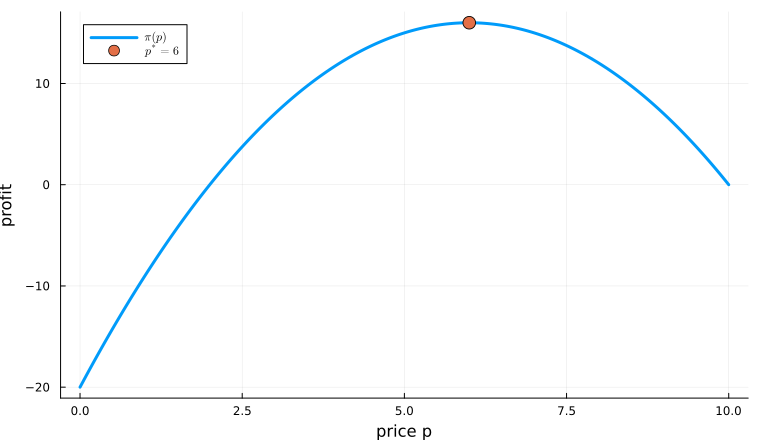

In [3]:
prices = range(0.0, one_sided.a / one_sided.b; length=301)
profits = [monopoly_profit(p; one_sided...) for p in prices]

plot(prices, profits; xlabel="price p", ylabel="profit", label=L"\pi(p)")
scatter!([p_mono], [monopoly_profit(p_mono; one_sided...)]; markersize=7, label=L"p^*=6")

### Benchmark Result

- With $a=10$, $b=1$, and $c=2$, the curve peaks at $p^*=6$
- A firm selling to one group never sets its best price below cost
- Below cost, every sale loses money, and nothing elsewhere makes up the loss
- Keep that logic in mind—the platform result will break it


## Build 2: Two Sides Must Meet

- Now the platform serves buyers $B$ and sellers $S$
- It sets per-interaction prices $p_B$ and $p_S$
- One buyer without a seller creates no interaction
- One seller without a buyer creates no interaction
- This complementarity is the whole model


### A Simplified Rochet–Tirole Model

- Prices here are **per interaction**: a buyer pays $p_B$ only when a transaction happens, and a seller pays $p_S$
- Willingness to transact on each side responds to its own price:

$$D_B(p_B)=a_B-b_Bp_B, \qquad D_S(p_S)=a_S-b_Sp_S.$$

- Wait: shouldn't buyer demand depend on how many sellers there are?
- Not here. Joining is free, so a buyer only asks "is this transaction worth $p_B$?"
- The other side enters through **volume**: each willing buyer can transact with each willing seller, so volume is $D_BD_S$
- One more willing seller adds $D_B$ transactions. Rochet and Tirole call this a **{term}`usage externality`**
- With cost $c$ per interaction, the margin is $p_B+p_S-c$
- Profit is

$$\pi(p_B,p_S)=(p_B+p_S-c)D_B(p_B)D_S(p_S).$$

- We restrict attention to prices with $D_B\geq 0$ and $D_S\geq 0$
- Later we switch to fees for *joining*, where the other side's size does enter demand


### The Cross-Side Externality

- Raise $p_B$ and some buyers leave
- A one-sided firm counts the lost buyer sales
- A platform also counts the value destroyed for **every seller**
- The same logic runs from sellers back to buyers
- This is a **cross-side network effect** inside the profit function
- Question: should the two sides still pay the same price?
- [this figure](#fig-cross-side-externality-loop) traces the chain in both directions


<a name="fig-cross-side-externality-loop" href="#fig-cross-side-externality-loop" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Raising $p_B$ loses buyer sales directly; because profit depends on $D_B\cdot D_S$, fewer buyers also means every seller completes fewer transactions, even though no seller leaves. The same chain runs in reverse from a seller-price increase back to buyers.

In [4]:
D_B(p_B, pars) = pars.aB - pars.bB * p_B
D_S(p_S, pars) = pars.aS - pars.bS * p_S

function platform_profit(p_B, p_S, pars)
    buyers = D_B(p_B, pars)
    sellers = D_S(p_S, pars)
    if buyers < 0 || sellers < 0
        return -Inf
    end
    return (p_B + p_S - pars.c) * buyers * sellers
end

symmetric = (aB=10.0, bB=1.0, aS=10.0, bS=1.0, c=2.0)

(aB = 10.0, bB = 1.0, aS = 10.0, bS = 1.0, c = 2.0)

## Build 3: Search the Price Surface

- Before taking derivatives, let the computer show us the landscape
- We evaluate profit on a grid of feasible prices
- The window includes subsidies and both choke prices
- Then we mark the best grid point


In [5]:
pB_grid = range(-2.0, symmetric.aB / symmetric.bB; length=241)
pS_grid = range(-2.0, symmetric.aS / symmetric.bS; length=241)
profit_grid = [platform_profit(pB, pS, symmetric) for pS in pS_grid, pB in pB_grid]

grid_index = argmax(profit_grid)
grid_solution = (pB=pB_grid[grid_index[2]], pS=pS_grid[grid_index[1]])
grid_profit = profit_grid[grid_index]
println("Best grid prices: ", grid_solution)
println("Best grid profit: ", round(grid_profit; digits=2))

Best grid prices: (

pB = 4.0, pS = 4.0)
Best grid profit: 216.0


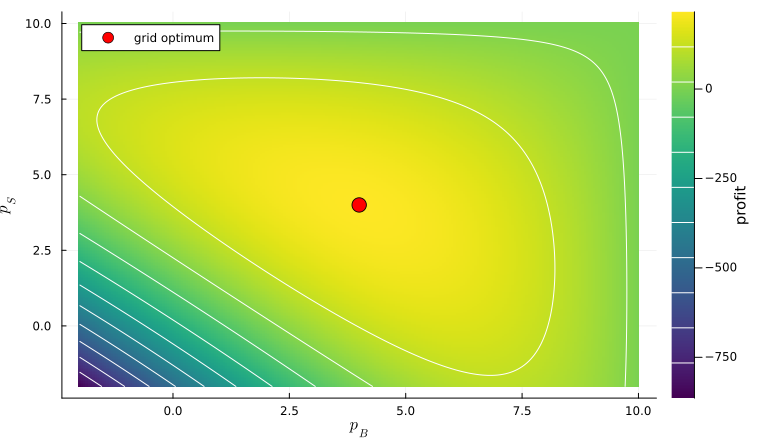

In [6]:
heatmap(pB_grid, pS_grid, profit_grid; xlabel=L"p_B", ylabel=L"p_S",
    color=:viridis, colorbar_title="profit", label=false)
contour!(pB_grid, pS_grid, profit_grid; levels=10, color=:white, linewidth=1, label=false)
scatter!([grid_solution.pB], [grid_solution.pS]; color=:red, markersize=8, label="grid optimum")

### What the Grid Says

- In the symmetric case, the best grid point is $(p_B,p_S)=(4,4)$
- Symmetric demand produces a symmetric **price structure**
- A grid is transparent and robust, but only approximates the optimum
- Can we recover the same answer from the first-order conditions?


## Derive the First-Order Conditions

- Write total per-interaction margin as $m=p_B+p_S-c$
- For positive participation, differentiating gives

$$\frac{\partial \pi}{\partial p_B}=D_S[D_B-b_Bm]=0,$$

$$\frac{\partial \pi}{\partial p_S}=D_B[D_S-b_Sm]=0.$$

- Substitute linear demand and divide by the slopes:

$$2p_B+p_S=\frac{a_B}{b_B}+c, \qquad p_B+2p_S=\frac{a_S}{b_S}+c.$$

- Solving yields

$$p_B^*=\frac{2}{3}\frac{a_B}{b_B}-\frac{1}{3}\frac{a_S}{b_S}+\frac{c}{3},$$

$$p_S^*=\frac{2}{3}\frac{a_S}{b_S}-\frac{1}{3}\frac{a_B}{b_B}+\frac{c}{3}.$$


### Detour: Newton's Method

- In [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb) we found fixed points with **bisection**: keep an interval where the function changes sign, then halve it
- Bisection is safe but slow: each step gains about one binary digit of accuracy. It also only works for one unknown
- Newton's method uses the slope instead of a bracket
- At the current guess $x_k$, replace $f$ with its tangent line and jump to where that line crosses zero:

$$x_{k+1}=x_k-\frac{f(x_k)}{f'(x_k)}.$$

- Near a root, the number of correct digits roughly **doubles** every step
- The cost: we need the derivative and a reasonable starting guess. Far from a root, or where $f'(x)\approx 0$, the jump can overshoot
- Try it on $f(x)=x^2-2$, whose root is $\sqrt{2}$
- Algorithm:
  1. Start with a guess $x_0$ and record it
  2. Evaluate $f(x_k)$ and $f'(x_k)$
  3. Set $x_{k+1}=x_k-f(x_k)/f'(x_k)$ and record it
  4. Repeat steps 2-3 for the requested number of steps


### Exercise 1: Code Newton's Method

- Fill in `newton_path` below, following steps 1-4
- Return a `Vector{Float64}` of length `steps + 1`: the starting guess followed by each new iterate
- Predict by hand: starting from $x_0=1$ on $x^2-2$, what is $x_1$?
- A second test uses a straight line: how many steps should Newton's method need there?


In [ ]:
root2_gap(x) = x^2 - 2
root2_slope(x) = 2x

"""
Take `steps` Newton steps on `f` (with derivative `fprime`) from the guess `x`.
Return a `Vector{Float64}` of length `steps + 1`: the starting guess followed by each new iterate.
"""
function newton_path(f, fprime, x; steps=5)
    path = Float64[]  # CHANGE ME: start the path with the initial guess
    for _ in 1:steps
        # TODO: steps 2-3 -- evaluate f and fprime at x, take the Newton step, record the new x
    end
    return nothing  # CHANGE ME
end


In [ ]:
# test code
function test_newton_path(f)
    same(got, want) = got !== nothing && length(got) == length(want) &&
        all(isapprox.(got, want; atol=1e-12))

    got = f(root2_gap, root2_slope, 1.0; steps=3)
    want = [1.0, 1.5, 1.4166666666666667, 1.4142156862745099]
    same(got, want) || error("x^2 - 2 from 1.0: expected $want, got $got")

    got = f(x -> x - 3, x -> 1.0, 0.0; steps=2)
    same(got, [0.0, 3.0, 3.0]) || error("x - 3 from 0.0: expected [0.0, 3.0, 3.0], got $got")

    println("correct!")
end

function run_tests()
    test_newton_path(newton_path)
end


In [ ]:
# uncomment the code below and run when you are ready to test your code
# run_tests()


- Once your tests pass, run the next cell to watch the error shrink


In [ ]:
guesses = newton_path(root2_gap, root2_slope, 1.0)
if guesses === nothing
    println("Finish `newton_path` above, then rerun this cell")
else
    [0:5 guesses abs.(guesses .- sqrt(2))]
end

### From One Equation to Two

- With a working `newton_path`, the error falls from about $10^{-1}$ to $10^{-12}$ in four steps; bisection would need about 40 halvings
- Our first-order conditions are **two** equations in two unknowns: $F(x)=0$ with $x=(p_B,p_S)$
- The derivative becomes a matrix of partial derivatives, the **Jacobian** $J$, with entries $J_{ij}=\partial F_i/\partial x_j$
- The tangent line becomes a tangent plane, and dividing by $f'$ becomes solving a linear system:

$$x_{k+1}=x_k-J(x_k)^{-1}F(x_k).$$

- In Julia, `J \ F` solves $J\Delta=F$ without forming the inverse
- `ForwardDiff.jacobian` computes $J$ by automatic differentiation, so we don't derive it by hand
- `newton_system` below runs these steps:
  1. Start at a guess $x_0$
  2. Evaluate the residual $F(x_k)$. If its largest entry is below the tolerance, stop and return $x_k$
  3. Compute the Jacobian $J(x_k)$
  4. Solve $J(x_k)\Delta=F(x_k)$ for the step $\Delta$
  5. Set $x_{k+1}=x_k-\Delta$ and return to step 2
  6. If the iteration limit passes first, report that Newton's method did not converge


In [7]:
function platform_focs(x, pars)
    p_B, p_S = x
    margin = p_B + p_S - pars.c
    buyers = D_B(p_B, pars)
    sellers = D_S(p_S, pars)
    return [sellers * (buyers - pars.bB * margin),
            buyers * (sellers - pars.bS * margin)]
end

function newton_system(f, x0; tolerance=1e-10, max_iterations=50)
    x = Float64.(x0)
    for iteration in 1:max_iterations
        residual = f(x)
        if norm(residual, Inf) < tolerance
            return (root=x, iterations=iteration - 1, residual=norm(residual, Inf))
        end
        jacobian = ForwardDiff.jacobian(f, x)
        x -= jacobian \ residual
    end
    error("Newton's method did not converge")
end

newton_system (generic function with 1 method)

In [8]:
closed_form_prices(pars) = (
    pB=(2 * pars.aB / pars.bB - pars.aS / pars.bS + pars.c) / 3,
    pS=(2 * pars.aS / pars.bS - pars.aB / pars.bB + pars.c) / 3,
)

newton_symmetric = newton_system(x -> platform_focs(x, symmetric), [2.0, 5.0])
analytic_symmetric = closed_form_prices(symmetric)
println("Newton prices: ", round.(newton_symmetric.root; digits=6))
println("Closed-form prices: ", analytic_symmetric)
println("Distance from grid solution: ",
    norm(newton_symmetric.root - [grid_solution.pB, grid_solution.pS]))

Newton prices: 

[4.0, 4.0]
Closed-form prices: (pB = 4.0, pS = 4.0)
Distance from grid solution: 0.0


### Three Routes, One Answer

- The grid search, Newton solver, and closed-form algebra all give $(4,4)$
- ForwardDiff supplies the Jacobian, but the Newton updates are ours
- Agreement across methods is evidence that the code matches the model
- Symmetry is reassuring—but it hides the interesting economics


## Break the Symmetry

- Let buyers be much more price-sensitive than sellers
- Set $b_B=4$ and $b_S=0.5$, with both intercepts at 10 and cost at 2
- Before computing: which side should the platform protect?
- Losing one buyer also reduces the value delivered to sellers


In [9]:
asymmetric = (aB=10.0, bB=4.0, aS=10.0, bS=0.5, c=2.0)
newton_asymmetric = newton_system(x -> platform_focs(x, asymmetric), [-4.0, 13.0])
analytic_asymmetric = closed_form_prices(asymmetric)
pB_asym, pS_asym = newton_asymmetric.root

println("Buyer price: ", round(pB_asym; digits=2))
println("Seller price: ", round(pS_asym; digits=2))
println("Total price: ", round(pB_asym + pS_asym; digits=2))
println("Per-interaction margin: ", round(pB_asym + pS_asym - asymmetric.c; digits=2))
println("Closed-form check: ", analytic_asymmetric)

Buyer price: -4.33


Seller price: 13.17
Total price: 8.83
Per-interaction margin: 6.83
Closed-form check: (pB = -4.333333333333333, pS = 13.166666666666666)


## Subsidize the Sensitive Side

- The optimal buyer price is about **−4.33**
- The optimal seller price is about **13.17**
- The platform pays buyers to participate and charges sellers for access to them
- Yet the total price is about 8.83 and the per-interaction margin is about 6.83
- Ladies' Night, cashback rewards, and free restaurant reservations fall out of the same first-order conditions
- A negative price is not irrational when it creates profitable activity on the other side


### Price Structure vs Price Level

- The **price level** is the total charge per interaction: $p_B+p_S$
- The **price structure** is how that total is divided between the two sides
- Holding $p_B+p_S$ fixed but changing the split changes participation and volume
- That would be impossible in a genuinely one-sided market
- This sensitivity to price structure is Rochet and Tirole's key definition of two-sidedness


## Comparative Statics

- One asymmetric example could be a coincidence
- Sweep buyer price sensitivity $b_B$ while holding the seller side fixed
- Trace both optimal prices and find the zero-price crossover
- Prediction: as buyers become easier to lose, buyers pay less and sellers pay more


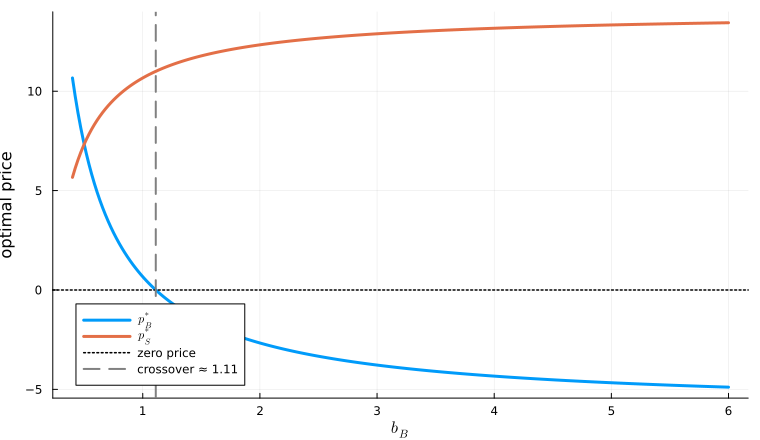

In [10]:
buyer_slopes = range(0.4, 6.0; length=240)
sweep_parameters = [merge(asymmetric, (bB=b,)) for b in buyer_slopes]
sweep_prices = closed_form_prices.(sweep_parameters)
buyer_prices = getproperty.(sweep_prices, :pB)
seller_prices = getproperty.(sweep_prices, :pS)
zero_crossover = 2 * asymmetric.aB / (asymmetric.aS / asymmetric.bS - asymmetric.c)

plot(buyer_slopes, buyer_prices; xlabel=L"b_B", ylabel="optimal price", label=L"p_B^*")
plot!(buyer_slopes, seller_prices; label=L"p_S^*")
hline!([0.0]; color=:black, linestyle=:dot, linewidth=1.5, label="zero price")
vline!([zero_crossover]; color=:gray, linestyle=:dash, linewidth=2,
    label="crossover ≈ $(round(zero_crossover; digits=2))")

### Reading the Sweep

- The buyer price crosses zero at $b_B\approx 1.11$ for these parameters
- Beyond that point, greater buyer sensitivity produces a larger buyer subsidy
- The seller price rises because sellers benefit from the participation that subsidy creates
- **A one-sided monopolist would NEVER price below cost; a platform does it routinely and rationally**
- The qualification matters: the platform earns revenue from the cross-side response


### Fleet Cards Ran This Experiment

- Trucking fleets give drivers fuel cards; truck stops accept them
- A typical transaction earns the card company \$2.00: \$0.50 from the fleet, \$1.50 from the truck stop (Evans & Schmalensee, *Matchmakers*, ch. 6)
- Price level: \$2.00. Price structure: 25% fleets, 75% stops
- It was not always tilted this way
  - Early on, fleets paid and truck stops were subsidized
  - Then a roughly even split
  - Late 1990s: fuel prices and competition squeezed fleets, and they became far more price sensitive
  - Around 2000, prices fell for fleets and rose for stops
- That is our sweep, played out by a real industry: $b_B$ rose, $p_B^*$ fell, $p_S^*$ rose
- [the diagram below](#fig-fleet-card-price-structure) tracks the price structure through all three eras


<a name="fig-fleet-card-price-structure" href="#fig-fleet-card-price-structure" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Fleet card pricing began with fleets paying the full fee, drifted to roughly even once truck stops joined in, and after fuel prices and competition made fleets far more price sensitive it settled near 25% fleets / 75% truck stops — on a typical \$2.00 transaction, \$0.50 from the fleet and \$1.50 from the truck stop.

### Who Decides Whether the Interaction Happens?

- Price sensitivity is one reason to go easy on a side. Here is another
- **Subsidize the side that chooses whether an interaction happens at all**
  - The fleet decides which stops its drivers may use
  - The searcher decides which search engine to open
  - The cardholder decides which card to present
- Lose that side and every participant on the other side loses volume
- Our $D_BD_S$ captures the gate, but not who initiates each interaction
- Platforms also choose *what* to price
  - **{term}`Access fees <access fee>`** charge for joining; **{term}`usage fees <usage fee>`** charge per interaction
  - OpenTable: restaurants pay a monthly fee plus a per-seat fee; diners pay nothing and earn rewards
  - Amex: cardholders pay an annual fee, then earn rewards on every swipe, a negative usage price
- When a platform charges to join, the other side's size enters each member's decision directly. We build that model next

## Build 4: Pay to Join

- So far, prices are per interaction. Many platforms instead charge to **join**: a dating-app subscription, a mall's monthly rent, a nightclub cover charge
- Now a buyer decides whether to join by asking how many sellers she gains access to, just as in [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb)
- Let $n_B$ and $n_S$ be the number of members on each side, and $p_B$, $p_S$ the membership fees
- Each buyer values each seller at $\alpha_B$; each seller values each buyer at $\alpha_S$
- A buyer's net price is her fee minus the value of the sellers she reaches: $p_B-\alpha_Bn_S$
- Membership responds to the net price:

$$n_B=a_B-b_B(p_B-\alpha_Bn_S), \qquad n_S=a_S-b_S(p_S-\alpha_Sn_B).$$

- This is a **{term}`membership externality`**: the cross-side effect now sits inside each demand curve


### Solving for Membership

- $n_B$ depends on $n_S$, and $n_S$ depends on $n_B$. For given fees, we need membership that is consistent on both sides
- This is the two-sided version of the {term}`fulfilled-expectations equilibrium` from [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb)
- Both equations are linear in $(n_B,n_S)$, so one linear solve finds it:

$$
\begin{bmatrix}1 & -b_B\alpha_B\\ -b_S\alpha_S & 1\end{bmatrix}
\begin{bmatrix}n_B\\ n_S\end{bmatrix}
=
\begin{bmatrix}a_B-b_Bp_B\\ a_S-b_Sp_S\end{bmatrix}.
$$

- We need $b_B\alpha_B\,b_S\alpha_S<1$. Otherwise each new member attracts more than one new member on the way back, and membership never settles
- If the solve gives a negative count on one side, that side stays empty and the other side's members get no cross-side value
- With a cost $f$ per member, profit is

$$\pi(p_B,p_S)=(p_B-f)\,n_B+(p_S-f)\,n_S.$$


In [ ]:
function members(p_B, p_S, m)
    A = [1.0 -m.bB * m.αB; -m.bS * m.αS 1.0]
    rhs = [m.aB - m.bB * p_B, m.aS - m.bS * p_S]
    n_B, n_S = A \ rhs
    n_B >= 0 && n_S >= 0 && return [n_B, n_S]
    # Corners: if one side is empty, the other faces no cross-side value
    only_S = max(rhs[2], 0.0)
    rhs[1] + m.bB * m.αB * only_S <= 0 && return [0.0, only_S]
    only_B = max(rhs[1], 0.0)
    rhs[2] + m.bS * m.αS * only_B <= 0 && return [only_B, 0.0]
    return [0.0, 0.0]
end

function join_profit(p_B, p_S, m)
    n_B, n_S = members(p_B, p_S, m)
    return (p_B - m.f) * n_B + (p_S - m.f) * n_S
end

membership = (aB=10.0, bB=1.0, aS=10.0, bS=1.0, f=2.0, αB=0.1, αS=1.2)
@assert membership.bB * membership.αB * membership.bS * membership.αS < 1

### Equal Sensitivity, Unequal Value

- Both sides are equally price sensitive: $b_B=b_S=1$, equal intercepts, member cost $f=2$
- One asymmetry: sellers value buyers a lot ($\alpha_S=1.2$); buyers barely care about sellers ($\alpha_B=0.1$)
- Our per-interaction model would charge these two sides the same price
- Prediction: who pays less now?


In [ ]:
fee_grid = range(-10.0, 15.0; length=501)
join_profits = [join_profit(pB, pS, membership) for pS in fee_grid, pB in fee_grid]
best_fees = argmax(join_profits)
pB_join, pS_join = fee_grid[best_fees[2]], fee_grid[best_fees[1]]
nB_join, nS_join = members(pB_join, pS_join, membership)

(p_B=pB_join, p_S=pS_join, n_B=round(nB_join; digits=2), n_S=round(nS_join; digits=2))

(p_B = -0.3, p_S = 12.3, n_B = 11.44, n_S = 11.43)

### Subsidize the Side the Other Side Values

- Buyers pay about $-0.30$: the platform pays them to join, even though each costs $f=2$ to serve
- Sellers pay about $12.30$
- Price sensitivity is identical, so this subsidy is not about which side is easier to lose
- Each extra buyer is worth $\alpha_S=1.2$ to **every** seller, and the platform collects that value through the seller fee
- Armstrong (2006) derives the optimal fee in this model:

$$p_B^*=\underbrace{f}_{\text{cost}}+\underbrace{\frac{n_B}{b_B}}_{\text{one-sided markup}}-\underbrace{\alpha_Sn_S}_{\text{value to all sellers}}.$$

- The last term is the discount: one more buyer creates $\alpha_S$ for each of $n_S$ sellers
- Two models, two reasons to subsidize a side:
  - Per-interaction fees: subsidize the side that is **easier to lose** (large $b$)
  - Membership fees: **discount** the side the other side values most (large $\alpha$ on the other side). A big enough discount, as here, pushes the fee below cost or below zero


In [ ]:
armstrong_pB = membership.f + nB_join / membership.bB - membership.αS * nS_join
(grid_search=pB_join, armstrong_rule=round(armstrong_pB; digits=2))

(grid_search = -0.3, armstrong_rule = -0.27)

### Pricing Can Help a Platform Ignite

- Subsidizing one side can help solve the **chicken-and-egg problem**
- Reaching **critical mass** strengthens cross-side participation and may trigger **tipping**
- Same-side congestion or rivalry can push in the opposite direction
- Our static linear model compresses those dynamics into demand curves
- The lesson is not “always subsidize buyers”; it is “price the {term}`network effect`, not just the transaction”


## Platforms in Court

- **Ohio v. American Express** treated credit-card transactions as a two-sided platform market
  - Evaluating merchant fees alone can miss cardholder rewards and changes in transaction volume
- **Epic Games v. Apple** put platform market definition and rules between users and developers at center stage
  - A developer commission cannot be interpreted without asking how users and developers respond together
- Courts increasingly require two-sided analysis when the relevant market links both groups
- Two-sided analysis does not mean every platform practice is efficient or lawful


### Multihoming and the Competitive Bottleneck

- **{term}`Multihoming <multihoming>`** means participating on more than one platform
- Armstrong's {term}`competitive-bottleneck <competitive bottleneck>` insight in one line:
  - Platforms court the side that single-homes and tax the side that multihomes
- [the diagram below](#fig-competitive-bottleneck) shows why: access to the {term}`single-homers <single-homing>` is what rival platforms compete over
- Winning a single-homing participant can give access to that participant across competing platforms
- This adds competitive strategy to the cross-side logic in our monopoly model


<a name="fig-competitive-bottleneck" href="#fig-competitive-bottleneck" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Single-homing users are split between rival platforms and courted with low or negative prices, while multihoming users connect to both platforms and are taxed with higher prices, because access to the single-homers is what the platforms are really competing for.

### Exercise 2: Platform or Tariff?

- Consider Costco membership, Amazon Prime, and a farmers-market stall fee
- Is each example two-sided pricing or a plain two-part tariff?
- Identify the sides and the cross-side interaction, if any
- Use the test: would changing the **price structure** while holding the **price level** fixed change volume?
- Be ready to defend why a label such as “membership” or “fee” is not enough


### Exercise 3: More Sellers

- Return to the asymmetric parameterization
- Double the seller intercept from $a_S=10$ to $a_S=20$
- Re-solve for $p_B^*$ and $p_S^*$
- Which price rises? Which falls?
- Explain the result using the value of attracting the opposite side—not algebra alone


In [11]:
more_sellers = merge(asymmetric, (aS=20.0,))

# TODO: compute the new optimum with closed_form_prices or newton_system
# TODO: compare both prices with analytic_asymmetric
# TODO: explain why the changes have opposite signs

(aB = 10.0, bB = 4.0, aS = 20.0, bS = 0.5, c = 2.0)

### Exercise 4: Which Value Matters?

- Use the membership model from Build 4
- Hold $\alpha_B=0.1$ and sweep $\alpha_S$ from 0 to 1.5
- Plot both optimal fees against $\alpha_S$, with a horizontal line at the cost $f$
- At what $\alpha_S$ does the buyer fee fall below cost? Below zero?
- Now make buyers more price sensitive ($b_B=2$) and set $\alpha_S=0.6$. Do the two reasons to subsidize buyers add up or pull against each other?
- Return to Ladies' Night: which group's $\alpha$ is larger at a nightclub, and does the membership model explain a \$0 cover charge?


In [ ]:
alpha_S_values = range(0.0, 1.5; length=31)

# TODO: for each αS, build merge(membership, (αS=αS,)) and find the best fees on fee_grid
# TODO: plot both fees against αS and add hline!([membership.f])
# TODO: repeat with bB = 2.0 and αS = 0.6; compare the buyer fee with the αS = 0.6, bB = 1 case
nothing

### Exercise 5: Design a Compute Marketplace

- You run a GPU-compute marketplace matching AI startups to datacenter owners
- This previews our AI agents unit: startups deploy agents but need scarce compute
- Which side would you subsidize at launch, and why?
- Discuss price sensitivity, cross-side value, the chicken-and-egg problem, and multihoming
- What evidence would make you reverse the subsidy?
- Design one non-price incentive that could help reach critical mass


## Takeaways

- A platform chooses a vector of prices, not one price
- Cross-side network effects make participation on each side affect the value of the other
- The price-sensitive side may optimally pay zero or receive a subsidy
- When platforms charge to join, the side the other side values most may be subsidized instead
- Price structure can change volume even when the total price level does not
- Grid search, hand-derived first-order conditions, and Newton's method tell the same story
- As with {term}`Braess' paradox`, familiar pieces can produce a surprising system-level result


## Next Time: Markets Without Prices

- Prices are one way to clear a market—but some markets refuse prices entirely
- Kidneys. Medical residencies. School seats.
- These markets **match** instead of price
- We will define a **{term}`stable matching`** and ask whether any **{term}`blocking pair`** can upset it
- Then we will build the {term}`deferred-acceptance algorithm <deferred acceptance>` that helped win a Nobel
